# Exploratory analysis

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sqlite3

root = Path.cwd()
if not (root / "churn.db").exists() and (root.parent / "churn.db").exists():
    os.chdir(root.parent)

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (8, 5)

conn = sqlite3.connect("churn.db")
df = pd.read_sql("SELECT * FROM features", conn)
conn.close()

print(df.shape)
print(df["churn"].value_counts(normalize=True).round(3))
df.head()

Matplotlib is building the font cache; this may take a moment.


(28382, 30)
churn
0    0.815
1    0.185
Name: proportion, dtype: float64


,customer_id,vintage,age,gender,dependents,occupation,city,customer_nw_category,branch_code,current_balance,...,last_transaction,has_last_txn,recency_days,freq_score,monetary_flow,balance_change,debit_trend,r_score,m_score,rfm_segment
0,862,2335,40,Female,0.0,self_employed,732.0,3,639,3328.77,...,NaN,0,999.0,0,0.04,2.74,1.0,1,1,Dormant
1,1232,1996,59,Male,0.0,self_employed,745.0,2,1093,3099.14,...,NaN,0,999.0,0,0.04,87.49,1.0,1,1,Dormant
2,1833,1531,49,Female,0.0,self_employed,1465.0,2,191,2077.91,...,NaN,0,999.0,0,0.04,135.71,1.0,1,1,Dormant
3,2936,1967,49,Male,0.0,salaried,578.0,2,2045,1732.34,...,NaN,0,999.0,0,0.04,0.00,1.0,1,1,Dormant
4,3287,2243,73,Male,0.0,self_employed,51.0,2,131,6133.74,...,NaN,0,999.0,0,0.04,2.43,1.0,1,1,Dormant


## Churn rate by recency (`r_score`) and monetary (`m_score`)

`r_score` 5 is most recent; `m_score` 5 is highest flow. If churn rises as recency falls, the RFM features are doing their job.

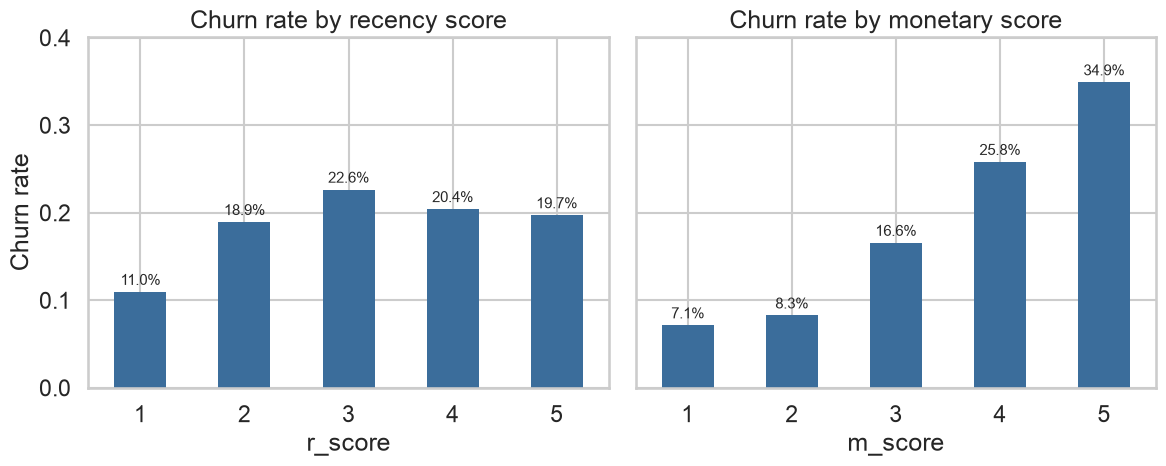

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, col, title in [
    (axes[0], "r_score", "Churn rate by recency score"),
    (axes[1], "m_score", "Churn rate by monetary score"),
]:
    rates = df.groupby(col)["churn"].mean().sort_index()
    rates.plot(kind="bar", ax=ax, color="#3b6d9b", edgecolor="none")
    ax.set_title(title)
    ax.set_xlabel(col)
    ax.set_ylabel("Churn rate")
    ax.set_ylim(0, max(0.4, rates.max() * 1.15))
    ax.tick_params(axis="x", rotation=0)
    for i, v in enumerate(rates):
        ax.text(i, v + 0.008, f"{v:.1%}", ha="center", fontsize=11)

plt.tight_layout()
plt.savefig("outputs/churn_by_rfm_scores.png", dpi=150, bbox_inches="tight")
plt.show()

## Churn by occupation and customer net-worth category

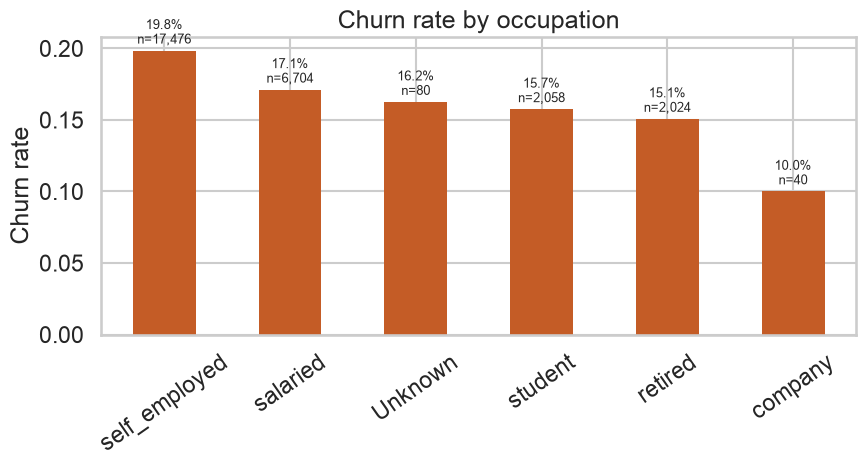

,churn_rate,n
occupation,,
self_employed,0.198386,17476
salaried,0.171092,6704
Unknown,0.162500,80
student,0.157434,2058
retired,0.150692,2024
company,0.100000,40


In [3]:
occ = (
    df.assign(occupation=df["occupation"].fillna("Unknown"))
    .groupby("occupation")["churn"]
    .agg(churn_rate="mean", n="size")
    .sort_values("churn_rate", ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 5))
occ["churn_rate"].plot(kind="bar", ax=ax, color="#c45c26", edgecolor="none")
ax.set_title("Churn rate by occupation")
ax.set_ylabel("Churn rate")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=35)
for i, (rate, n) in enumerate(zip(occ["churn_rate"], occ["n"])):
    ax.text(i, rate + 0.005, f"{rate:.1%}\nn={n:,}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("outputs/churn_by_occupation.png", dpi=150, bbox_inches="tight")
plt.show()
occ

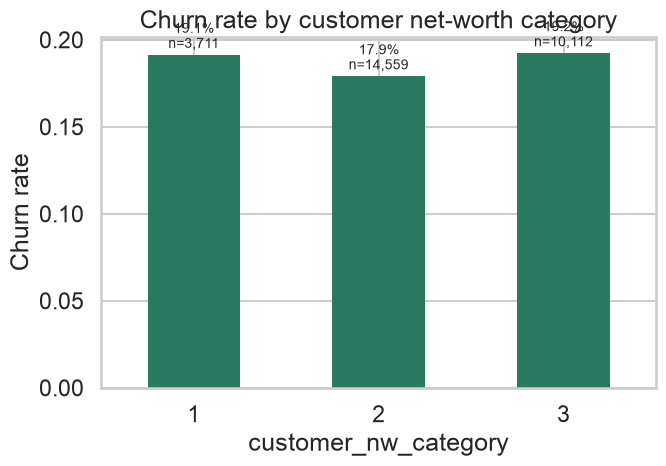

,churn_rate,n
customer_nw_category,,
1,0.191323,3711
2,0.178996,14559
3,0.192247,10112


In [4]:
nw = df.groupby("customer_nw_category")["churn"].agg(churn_rate="mean", n="size").sort_index()

fig, ax = plt.subplots(figsize=(7, 5))
nw["churn_rate"].plot(kind="bar", ax=ax, color="#2a7a62", edgecolor="none")
ax.set_title("Churn rate by customer net-worth category")
ax.set_xlabel("customer_nw_category")
ax.set_ylabel("Churn rate")
ax.tick_params(axis="x", rotation=0)
for i, (rate, n) in enumerate(zip(nw["churn_rate"], nw["n"])):
    ax.text(i, rate + 0.004, f"{rate:.1%}\nn={n:,}", ha="center", fontsize=10)
plt.tight_layout()
plt.savefig("outputs/churn_by_nw_category.png", dpi=150, bbox_inches="tight")
plt.show()
nw

## Balance change: churners vs non-churners

`balance_change` is current balance minus previous month-end balance. Extreme outliers are hidden so the typical shift is readable.

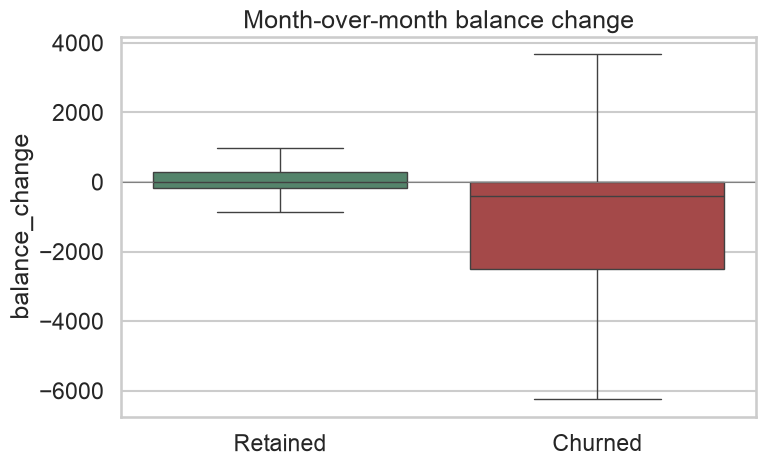

,count,mean,std,min,25%,50%,75%,max
status,,,,,,,,
Churned,5260.0,-2888.9,21020.7,-869454.6,-2500.5,-398.6,0.0,356766.9
Retained,23122.0,515.8,11482.8,-688056.9,-172.3,0.0,285.7,574712.4


In [5]:
plot_df = df[["churn", "balance_change"]].copy()
plot_df["status"] = plot_df["churn"].map({0: "Retained", 1: "Churned"})

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=plot_df,
    x="status",
    y="balance_change",
    showfliers=False,
    hue="status",
    palette={"Retained": "#4c8c6a", "Churned": "#b33a3a"},
    legend=False,
    ax=ax,
)
ax.axhline(0, color="gray", lw=0.8)
ax.set_title("Month-over-month balance change")
ax.set_xlabel("")
ax.set_ylabel("balance_change")
plt.tight_layout()
plt.savefig("outputs/balance_change_by_churn.png", dpi=150, bbox_inches="tight")
plt.show()

plot_df.groupby("status")["balance_change"].describe().round(1)

## Correlation heatmap of numeric features

`city` and `branch_code` are excluded here for the same reason they are dropped later: high-cardinality identifiers, not useful numeric signal.

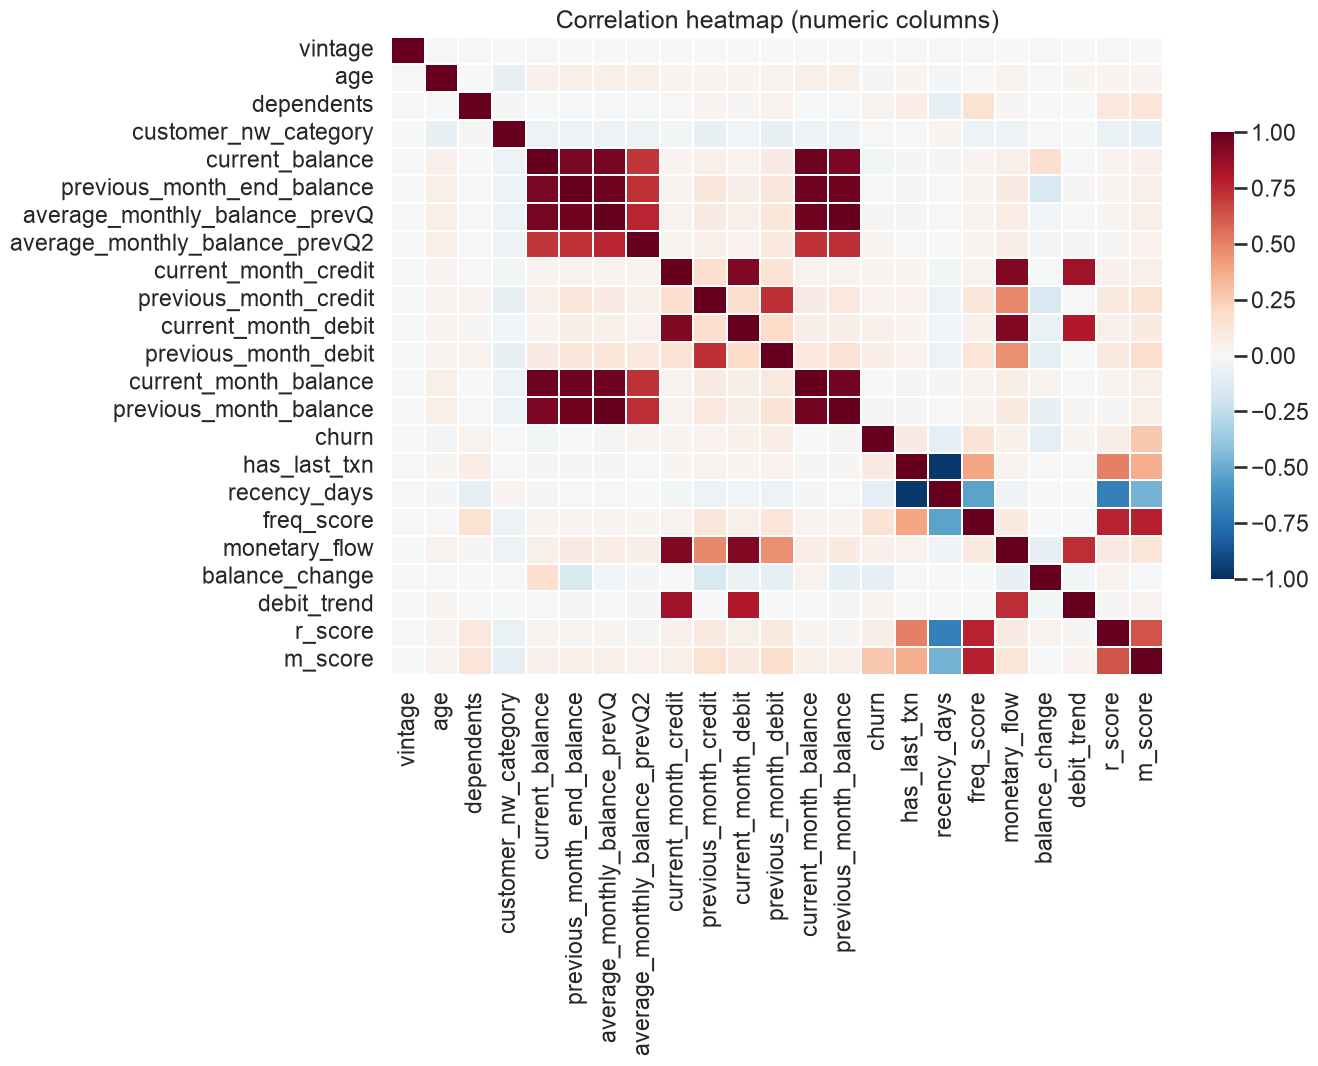

churn                   1.000000
m_score                 0.265994
freq_score              0.139041
recency_days            0.096508
balance_change          0.095714
has_last_txn            0.085258
previous_month_debit    0.073058
r_score                 0.069154
monetary_flow           0.049217
current_month_debit     0.048041
Name: churn, dtype: float64

In [6]:
id_like = {"customer_id", "city", "branch_code"}
num = df.select_dtypes(include="number").drop(columns=list(id_like), errors="ignore")
corr = num.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    corr,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=False,
    linewidths=0.2,
    ax=ax,
    cbar_kws={"shrink": 0.7},
)
ax.set_title("Correlation heatmap (numeric columns)")
plt.tight_layout()
plt.savefig("outputs/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

corr["churn"].abs().sort_values(ascending=False).head(10)